# Function Approximation using MLP (PyTorch Edition)
> **Chuyển đổi từ Keras sang PyTorch** — Thành viên 1: Lý Hồng Hưng (MSSV: 3123411132)
> - **Mục tiêu**: Xấp xỉ hàm mật độ xác suất Gaussian 2D bằng mạng Multi-Layer Perceptron (MLP).
> - **Các thay đổi chính từ Keras → PyTorch**:
>   - `Model(inputs=Input(2), outputs=Dense(...))` → lớp `GaussMLP(nn.Module)` gồm `nn.Linear` + `nn.Sigmoid`.
>   - Khởi tạo trọng số `xavier_uniform_` & bias bằng `0` để tương đồng với khởi tạo mặc định (`glorot_uniform`, `zeros`) của Keras.
>   - `model.compile(loss='mean_squared_error', optimizer=SGD(lr=0.01))` + `model.fit()` → `nn.MSELoss()` + `optim.SGD(..., lr=0.01)` + vòng lặp huấn luyện `DataLoader`.
>   - Đảm bảo nhãn đầu ra có shape `(N, 1)` để khớp đầu ra mạng `(N, 1)` khi tính `nn.MSELoss()`.

# (1) import libraries

In [ ]:
import time
import numpy as np
from scipy.stats import multivariate_normal
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import clear_output

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Cố định seed và chọn thiết bị (GPU nếu có, ngược lại CPU)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Using device   :", device)

PyTorch version: 2.14.1+cu130
Using device   : cuda


# (2) data preparation

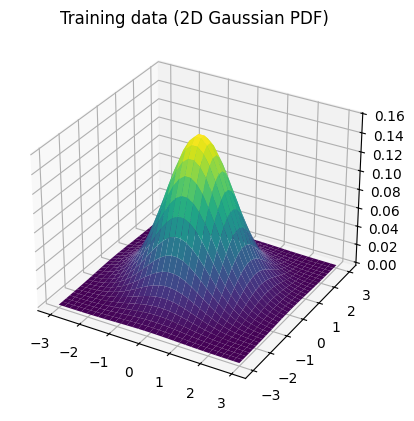

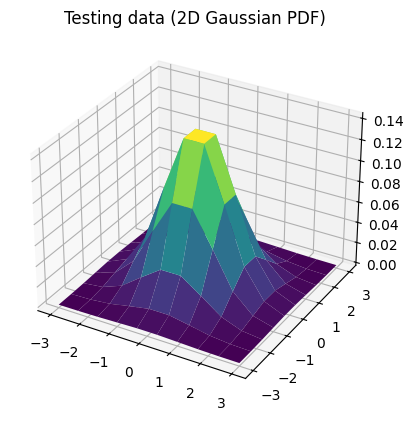

x_train: (1024, 2), y_train: (1024,)
x_test : (100, 2), y_test : (100,)


In [ ]:
# training ------------------------------
A = 32j
x1_tr, x2_tr = np.mgrid[-3.0:3.0:A, -3.0:3.0:A]
x1x2_tr = np.column_stack([x1_tr.flat, x2_tr.flat])

mu = np.array([0.0, 0.0])
covariance = np.diag([1, 1])

y_tr_grid = multivariate_normal.pdf(x1x2_tr, mean=mu, cov=covariance)
y_tr_grid = y_tr_grid.reshape(x1_tr.shape)

x_train = x1x2_tr.astype(np.float32)
y_train = y_tr_grid.flatten().astype(np.float32)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(x1_tr, x2_tr, y_tr_grid, cmap='viridis')
plt.title('Training data (2D Gaussian PDF)')
plt.show()

# testing -------------------------------
A = 10j
x1_te, x2_te = np.mgrid[-3.0:3.0:A, -3.0:3.0:A]
x1x2_te = np.column_stack([x1_te.flat, x2_te.flat])

y_te_grid = multivariate_normal.pdf(x1x2_te, mean=mu, cov=covariance)
y_te_grid = y_te_grid.reshape(x1_te.shape)

x_test = x1x2_te.astype(np.float32)
y_test = y_te_grid.flatten().astype(np.float32)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(x1_te, x2_te, y_te_grid, cmap='viridis')
plt.title('Testing data (2D Gaussian PDF)')
plt.show()

print(f"x_train: {x_train.shape}, y_train: {y_train.shape}")
print(f"x_test : {x_test.shape}, y_test : {y_test.shape}")

# (3) MLP (PyTorch `nn.Module`)

In [ ]:
class GaussMLP(nn.Module):
    """MLP 1 lớp ẩn xấp xỉ hàm Gaussian 2D (tương đương gauss_mlp trong Keras)."""
    def __init__(self, B=16):
        super().__init__()
        # 2 input nodes -> B hidden nodes (Sigmoid) -> 1 output node (Sigmoid)
        self.fc = nn.Linear(2, B)
        self.act1 = nn.Sigmoid()
        self.gauss_apxm = nn.Linear(B, 1)
        self.act2 = nn.Sigmoid()

        # Khởi tạo Xavier/Glorot uniform & bias = 0 giống mặc định của Keras Dense
        nn.init.xavier_uniform_(self.fc.weight)
        nn.init.zeros_(self.fc.bias)
        nn.init.xavier_uniform_(self.gauss_apxm.weight)
        nn.init.zeros_(self.gauss_apxm.bias)

    def forward(self, x):
        x = self.act1(self.fc(x))
        out = self.act2(self.gauss_apxm(x))
        return out


def train_and_evaluate(x_tr_np, y_tr_np, x_all_tr_np, y_all_tr_np, x_te_np, y_te_np,
                       B=16, epochs=100, batch_size=128, lr=0.01):
    """Khởi tạo, huấn luyện và tính MSE trên tập train & test cho GaussMLP."""
    model = GaussMLP(B=B).to(device)
    criterion = nn.MSELoss()
    optimizer = optim.SGD(model.parameters(), lr=lr)

    # Lưu ý quan trọng trong PyTorch: y phải có shape (N, 1) để khớp output (N, 1) của mô hình
    train_ds = TensorDataset(
        torch.from_numpy(x_tr_np).float(),
        torch.from_numpy(y_tr_np).float().unsqueeze(1),
    )
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)

    # Vòng lặp huấn luyện (tương đương model.fit)
    model.train()
    for _ in range(epochs):
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            preds = model(bx)
            loss = criterion(preds, by)
            loss.backward()
            optimizer.step()

    # Đánh giá trên toàn bộ tập train và test (tương đương model.evaluate)
    model.eval()
    with torch.no_grad():
        x_tr_t = torch.from_numpy(x_all_tr_np).float().to(device)
        y_tr_t = torch.from_numpy(y_all_tr_np).float().unsqueeze(1).to(device)
        tr_loss = criterion(model(x_tr_t), y_tr_t).item()

        x_te_t = torch.from_numpy(x_te_np).float().to(device)
        y_te_t = torch.from_numpy(y_te_np).float().unsqueeze(1).to(device)
        te_loss = criterion(model(x_te_t), y_te_t).item()

    return model, tr_loss, te_loss

# Kiểm tra nhanh kiến trúc mô hình
sample_model = GaussMLP(B=16)
print(sample_model)

GaussMLP(
  (fc): Linear(in_features=2, out_features=16, bias=True)
  (act1): Sigmoid()
  (gauss_apxm): Linear(in_features=16, out_features=1, bias=True)
  (act2): Sigmoid()
)


# (4) training and evaluating MLP

### (4.1) Number of training samples (A) (no. of hidden nodes (B) = 16 and no. of epochs (C) = 100)

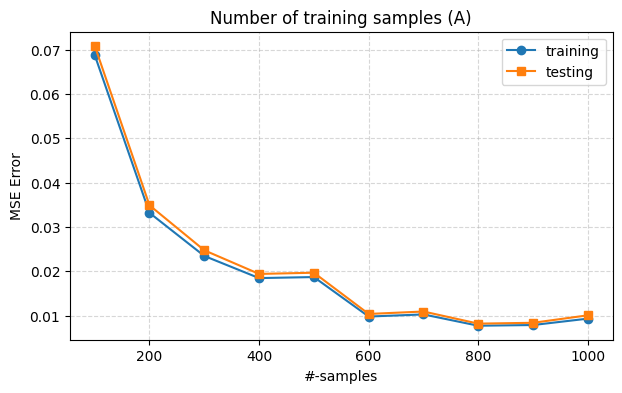

Hoàn thành thí nghiệm (4.1) trong 17.26 giây
Final (A=1000): Train MSE = 0.009348 | Test MSE = 0.010097


In [ ]:
train_error = []
test_error = []
tot_train = 1001
A_array = []

B = 16
C = 100
lr = 0.01
batch_size = 128

start_time = time.time()
for A in np.arange(100, tot_train, 100):
    sel_indx = np.random.choice(range(1, tot_train), size=A, replace=False)

    _, tr_loss, te_loss = train_and_evaluate(
        x_train[sel_indx], y_train[sel_indx],
        x_train, y_train, x_test, y_test,
        B=B, epochs=C, batch_size=batch_size, lr=lr
    )

    train_error.append(tr_loss)
    test_error.append(te_loss)
    A_array.append(A)

    # Vẽ mối quan hệ giữa số mẫu huấn luyện (A) và sai số MSE
    clear_output(wait=True)
    plt.figure(figsize=(7, 4))
    plt.plot(A_array, train_error, marker='o', label='training')
    plt.plot(A_array, test_error, marker='s', label='testing')
    plt.legend()
    plt.title('Number of training samples (A)')
    plt.xlabel('#-samples')
    plt.ylabel('MSE Error')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

print(f"Hoàn thành thí nghiệm (4.1) trong {time.time() - start_time:.2f} giây")
print(f"Final (A={A_array[-1]}): Train MSE = {train_error[-1]:.6f} | Test MSE = {test_error[-1]:.6f}")

### (4.2) Number of hidden nodes (B) (no. of training samples (A) = 800 and no. of epochs (C) = 100)

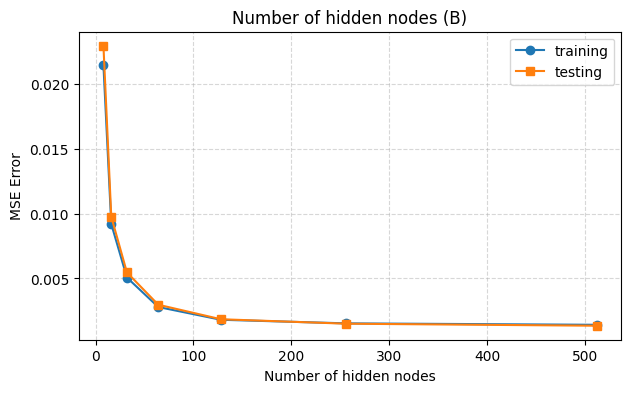

Hoàn thành thí nghiệm (4.2) trong 10.03 giây
Final (B=512): Train MSE = 0.001426 | Test MSE = 0.001354


In [ ]:
train_error = []
test_error = []
B_array = []
tot_train = 1001

A = 800
B = 8
C = 100
lr = 0.01
batch_size = 128

start_time = time.time()
while B <= 512:
    sel_indx = np.random.choice(range(1, tot_train), size=A, replace=False)

    _, tr_loss, te_loss = train_and_evaluate(
        x_train[sel_indx], y_train[sel_indx],
        x_train, y_train, x_test, y_test,
        B=B, epochs=C, batch_size=batch_size, lr=lr
    )

    train_error.append(tr_loss)
    test_error.append(te_loss)
    B_array.append(B)

    # Vẽ mối quan hệ giữa số nút ẩn (B) và sai số MSE
    clear_output(wait=True)
    plt.figure(figsize=(7, 4))
    plt.plot(B_array, train_error, marker='o', label='training')
    plt.plot(B_array, test_error, marker='s', label='testing')
    plt.legend()
    plt.title('Number of hidden nodes (B)')
    plt.xlabel('Number of hidden nodes')
    plt.ylabel('MSE Error')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

    B *= 2

print(f"Hoàn thành thí nghiệm (4.2) trong {time.time() - start_time:.2f} giây")
print(f"Final (B={B_array[-1]}): Train MSE = {train_error[-1]:.6f} | Test MSE = {test_error[-1]:.6f}")

### (4.3) Number of epochs (C) (no. of training samples (A) = 800 and no. of hidden nodes (B) = 128)

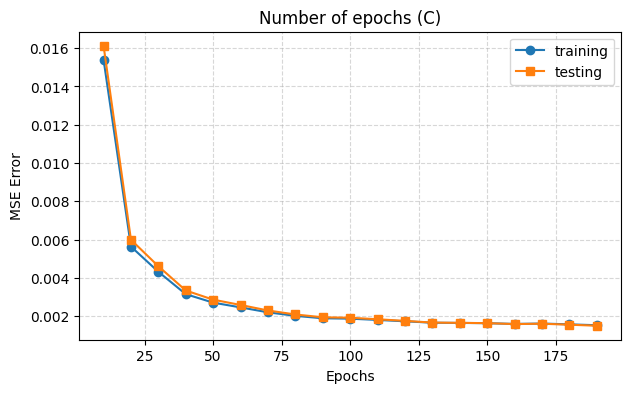

Hoàn thành thí nghiệm (4.3) trong 27.46 giây
Final (C=190): Train MSE = 0.001520 | Test MSE = 0.001494


In [ ]:
train_error = []
test_error = []
tot_train = 1001
C_array = []

A = 800
B = 128
lr = 0.01
batch_size = 128
last_model = None

start_time = time.time()
for C in np.arange(10, 200, 10):
    sel_indx = np.random.choice(range(1, tot_train), size=A, replace=False)

    last_model, tr_loss, te_loss = train_and_evaluate(
        x_train[sel_indx], y_train[sel_indx],
        x_train, y_train, x_test, y_test,
        B=B, epochs=int(C), batch_size=batch_size, lr=lr
    )

    train_error.append(tr_loss)
    test_error.append(te_loss)
    C_array.append(C)

    # Vẽ mối quan hệ giữa số epochs (C) và sai số MSE
    clear_output(wait=True)
    plt.figure(figsize=(7, 4))
    plt.plot(C_array, train_error, marker='o', label='training')
    plt.plot(C_array, test_error, marker='s', label='testing')
    plt.legend()
    plt.title('Number of epochs (C)')
    plt.xlabel('Epochs')
    plt.ylabel('MSE Error')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

print(f"Hoàn thành thí nghiệm (4.3) trong {time.time() - start_time:.2f} giây")
print(f"Final (C={C_array[-1]}): Train MSE = {train_error[-1]:.6f} | Test MSE = {test_error[-1]:.6f}")

### (4.4) Trực quan hóa bề mặt dự đoán 3D của mô hình cuối cùng (so sánh với Ground Truth)

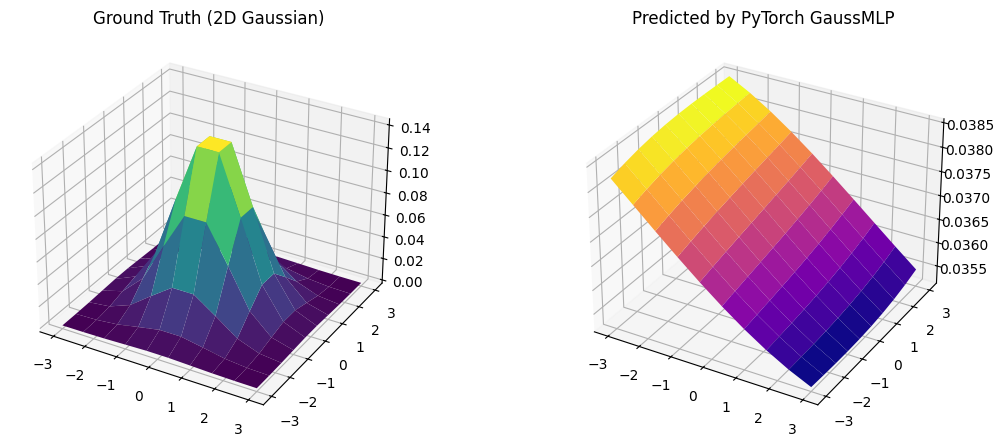

In [ ]:
# Dự đoán trên lưới kiểm tra bằng mô hình cuối cùng (A=800, B=128, C=190)
last_model.eval()
with torch.no_grad():
    y_pred_grid = last_model(torch.from_numpy(x_test).float().to(device)).cpu().numpy().reshape(x1_te.shape)

fig = plt.figure(figsize=(12, 4.5))
ax1 = fig.add_subplot(121, projection='3d')
ax1.plot_surface(x1_te, x2_te, y_te_grid, cmap='viridis')
ax1.set_title('Ground Truth (2D Gaussian)')

ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(x1_te, x2_te, y_pred_grid, cmap='plasma')
ax2.set_title('Predicted by PyTorch GaussMLP')
plt.tight_layout()
plt.show()